In [1]:
%pip install -q -U diffusers transformers accelerate safetensors
%pip install -q opencv-python pillow requests matplotlib rembg

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
!pip install "rembg[cpu]"
!pip install "rembg[gpu]"

In [3]:
import torch
import numpy as np
import cv2
import requests
import matplotlib.pyplot as plt

from PIL import Image, ImageFilter
from io import BytesIO
from rembg import remove, new_session

from torchvision import models
from torchvision.models import ResNet18_Weights

from diffusers import StableDiffusionXLInpaintPipeline

C:\Users\admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
if torch.cuda.is_available():
    device = "cuda"
    dtype = torch.float16
elif torch.backends.mps.is_available():
    device = "mps"
    dtype = torch.float16
else:
    device = "cpu"
    dtype = torch.float32

print("Device:", device)
print("Data type:", dtype)

if device == "cpu":
    print("Warning: SDXL may be extremely slow or run out of memory.")

Device: cpu
Data type: torch.float32


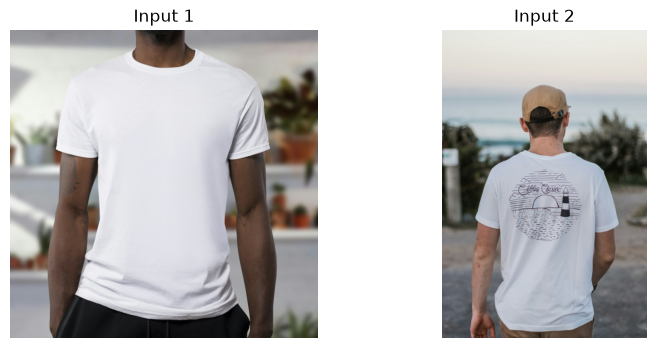

In [5]:
image_url_1 = "https://images.unsplash.com/photo-1521572163474-6864f9cf17ab?w=768"
image_url_2 = "https://images.unsplash.com/photo-1564859228273-274232fdb516?w=768"

response_1 = requests.get(image_url_1, timeout=30)
response_1.raise_for_status()

response_2 = requests.get(image_url_2, timeout=30)
response_2.raise_for_status()

image_1 = Image.open(BytesIO(response_1.content)).convert("RGB")
image_2 = Image.open(BytesIO(response_2.content)).convert("RGB")

plt.figure(figsize=(9, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_1)
plt.title("Input 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image_2)
plt.title("Input 2")
plt.axis("off")

plt.show()

In [6]:
from PIL import ImageOps

image_1 = ImageOps.pad(image_1, (768, 768), color="white")
image_2 = ImageOps.pad(image_2, (768, 768), color="white")

image_1_cv = cv2.cvtColor(np.array(image_1), cv2.COLOR_RGB2BGR)
image_2_cv = cv2.cvtColor(np.array(image_2), cv2.COLOR_RGB2BGR)

image_1_cv = cv2.fastNlMeansDenoisingColored(
    image_1_cv, None, 3, 3, 7, 21
)

image_2_cv = cv2.fastNlMeansDenoisingColored(
    image_2_cv, None, 3, 3, 7, 21
)

image_1 = Image.fromarray(
    cv2.cvtColor(image_1_cv, cv2.COLOR_BGR2RGB)
)

image_2 = Image.fromarray(
    cv2.cvtColor(image_2_cv, cv2.COLOR_BGR2RGB)
)

print("Preprocessing completed.")

Preprocessing completed.


In [7]:
weights = ResNet18_Weights.DEFAULT

cnn = models.resnet18(weights=weights)
cnn.fc = torch.nn.Identity()
cnn = cnn.to(device)
cnn.eval()

cnn_transform = weights.transforms()

print("Pretrained ResNet18 loaded.")

Pretrained ResNet18 loaded.


In [8]:
tensor_1 = cnn_transform(image_1).unsqueeze(0).to(device)
tensor_2 = cnn_transform(image_2).unsqueeze(0).to(device)

with torch.no_grad():
    features_1 = cnn(tensor_1).cpu().numpy().flatten()
    features_2 = cnn(tensor_2).cpu().numpy().flatten()

print("Input 1 features:", features_1.shape)
print("Input 2 features:", features_2.shape)

Input 1 features: (512,)
Input 2 features: (512,)


In [9]:
histogram_1 = cv2.calcHist(
    [image_1_cv], [0, 1, 2], None,
    [4, 4, 4], [0, 256, 0, 256, 0, 256]
).flatten()

histogram_2 = cv2.calcHist(
    [image_2_cv], [0, 1, 2], None,
    [4, 4, 4], [0, 256, 0, 256, 0, 256]
).flatten()

histogram_1 = histogram_1 / (histogram_1.sum() + 1e-8)
histogram_2 = histogram_2 / (histogram_2.sum() + 1e-8)

colour_features = np.stack([histogram_1, histogram_2])

colour_bipolar = np.where(
    colour_features > 0, 1, -1
).astype(np.float32)

cnn_features = np.stack([features_1, features_2])

cnn_bipolar = np.where(
    cnn_features >= np.median(
        cnn_features, axis=1, keepdims=True
    ),
    1, -1
).astype(np.float32)

print("Colour feature dimensions:", colour_bipolar.shape)
print("CNN feature dimensions:", cnn_bipolar.shape)

Colour feature dimensions: (2, 64)
CNN feature dimensions: (2, 512)


In [10]:
bam_weights = np.zeros((64, 512), dtype=np.float32)

for i in range(2):
    bam_weights += np.outer(
        colour_bipolar[i],
        cnn_bipolar[i]
    )

print("BAM training completed.")
print("Weight matrix:", bam_weights.shape)

BAM training completed.
Weight matrix: (64, 512)


In [11]:
recalled_cnn = np.sign(
    colour_bipolar[0] @ bam_weights
)

recalled_cnn[recalled_cnn == 0] = 1

recalled_colour = np.sign(
    recalled_cnn @ bam_weights.T
)

recalled_colour[recalled_colour == 0] = 1

recalled_cnn = np.sign(
    recalled_colour @ bam_weights
)

recalled_cnn[recalled_cnn == 0] = 1

print("Forward recall completed.")
print("Reverse recall completed.")

Forward recall completed.
Reverse recall completed.


In [12]:
mixed_colour = (histogram_1 + histogram_2) / 2
mixed_colour = mixed_colour / (mixed_colour.sum() + 1e-8)

mixed_bipolar = np.where(
    mixed_colour > 0, 1, -1
).astype(np.float32)

recalled_cnn = np.sign(mixed_bipolar @ bam_weights)
recalled_cnn[recalled_cnn == 0] = 1

recalled_colour = np.sign(recalled_cnn @ bam_weights.T)
recalled_colour[recalled_colour == 0] = 1

recalled_cnn = np.sign(recalled_colour @ bam_weights)
recalled_cnn[recalled_cnn == 0] = 1

similarity_1 = np.mean(recalled_cnn == cnn_bipolar[0])
similarity_2 = np.mean(recalled_cnn == cnn_bipolar[1])

selected_index = int(similarity_2 > similarity_1)

source_images = [image_1, image_2, [image_1, image_2][selected_index]]

print("BAM similarity to input 1:", similarity_1)
print("BAM similarity to input 2:", similarity_2)
print("Selected reference:", selected_index + 1)

BAM similarity to input 1: 0.70703125
BAM similarity to input 2: 1.0
Selected reference: 2


C:\Users\admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\rembg\session_factory.py:56: RuntimeWarning: CUDAExecutionProvider was requested but the session is running on CPU. onnxruntime could not load the provider, usually because the matching CUDA/cuDNN runtime libraries are missing or are a different major version than the onnxruntime-gpu build. Inference will be slow. See the onnxruntime stderr output above for the specific library that failed to load.
  return session_class(model_name, sess_opts, *args, **kwargs)


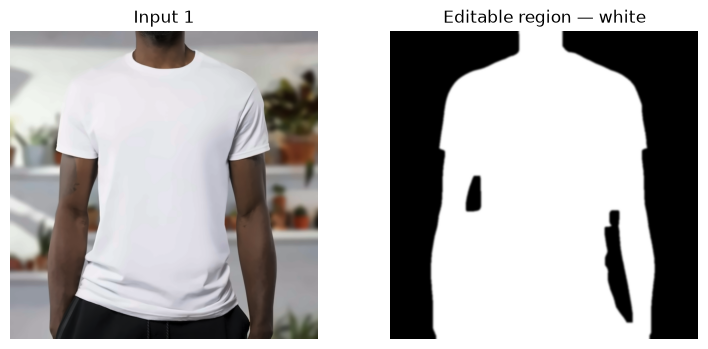

In [13]:
segmentation_session = new_session("u2net")

mask_1 = remove(
    image_1,
    session=segmentation_session,
    only_mask=True
).convert("L")

mask_2 = remove(
    image_2,
    session=segmentation_session,
    only_mask=True
).convert("L")

mask_array_1 = np.array(mask_1)
mask_array_2 = np.array(mask_2)

mask_array_1 = np.where(mask_array_1 > 127, 255, 0).astype(np.uint8)
mask_array_2 = np.where(mask_array_2 > 127, 255, 0).astype(np.uint8)

kernel = np.ones((15, 15), np.uint8)

mask_array_1 = cv2.erode(mask_array_1, kernel, iterations=1)
mask_array_2 = cv2.erode(mask_array_2, kernel, iterations=1)

mask_1 = Image.fromarray(mask_array_1).filter(ImageFilter.GaussianBlur(2))
mask_2 = Image.fromarray(mask_array_2).filter(ImageFilter.GaussianBlur(2))

plt.figure(figsize=(9, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_1)
plt.title("Input 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask_1, cmap="gray")
plt.title("Editable region — white")
plt.axis("off")

plt.show()

In [14]:
pipe = StableDiffusionXLInpaintPipeline.from_pretrained(
    "diffusers/stable-diffusion-xl-1.0-inpainting-0.1",
    torch_dtype=dtype,
    use_safetensors=True
)

if device == "cuda":
    pipe.enable_model_cpu_offload()
elif device == "mps":
    pipe = pipe.to("mps")
else:
    pipe = pipe.to("cpu")

pipe.enable_attention_slicing()

print("SDXL inpainting model loaded.")

C:\Users\admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading pipeline components...: 100%|██████████| 7/7 [00:03<00:00,  2.04it/s]


SDXL inpainting model loaded.


In [15]:
source_images = [image_1, image_2, source_images[2]]
source_masks = [mask_1, mask_2, [mask_1, mask_2][selected_index]]

prompts = [
    "Professional apparel product photography, red cotton crew-neck T-shirt, bold black geometric graphic printed on the chest, realistic cotton fabric texture, clean white studio background, centered full garment, preserve the original garment silhouette, no model, no text, no watermark",

    "Professional apparel product photography, black cotton crew-neck T-shirt, bold red modern geometric graphic printed on the chest, realistic cotton fabric texture, clean white studio background, centered full garment, preserve the original garment silhouette, no model, no text, no watermark",

    "Professional apparel product photography, stylish red and black color-block streetwear T-shirt, original geometric chest graphic combining red and black, realistic cotton fabric texture, clean white studio background, centered full garment, preserve the original garment silhouette, no model, no text, no watermark"
]

negative_prompt = (
    "person, mannequin, hanger, extra sleeves, extra collar, "
    "deformed clothing, distorted garment, blurry, low quality, "
    "text, letters, logo, watermark, cropped T-shirt"
)

print("Three design prompts prepared.")

Three design prompts prepared.


In [16]:
generated_images = []

for i in range(3):
    print("Generating design", i + 1, "of 3...")

    result = pipe(
        prompt=prompts[i],
        negative_prompt=negative_prompt,
        image=source_images[i],
        mask_image=source_masks[i],
        height=768,
        width=768,
        num_inference_steps=30,
        guidance_scale=7.5,
        strength=0.85
    )

    generated_images.append(result.images[0])

    print("Design", i + 1, "completed.")

print("All three generation attempts finished.")

Generating design 1 of 3...


100%|██████████| 25/25 [06:54<00:00, 16.59s/it]


Design 1 completed.
Generating design 2 of 3...


100%|██████████| 25/25 [06:52<00:00, 16.50s/it]


Design 2 completed.
Generating design 3 of 3...


100%|██████████| 25/25 [06:45<00:00, 16.23s/it]


Design 3 completed.
All three generation attempts finished.


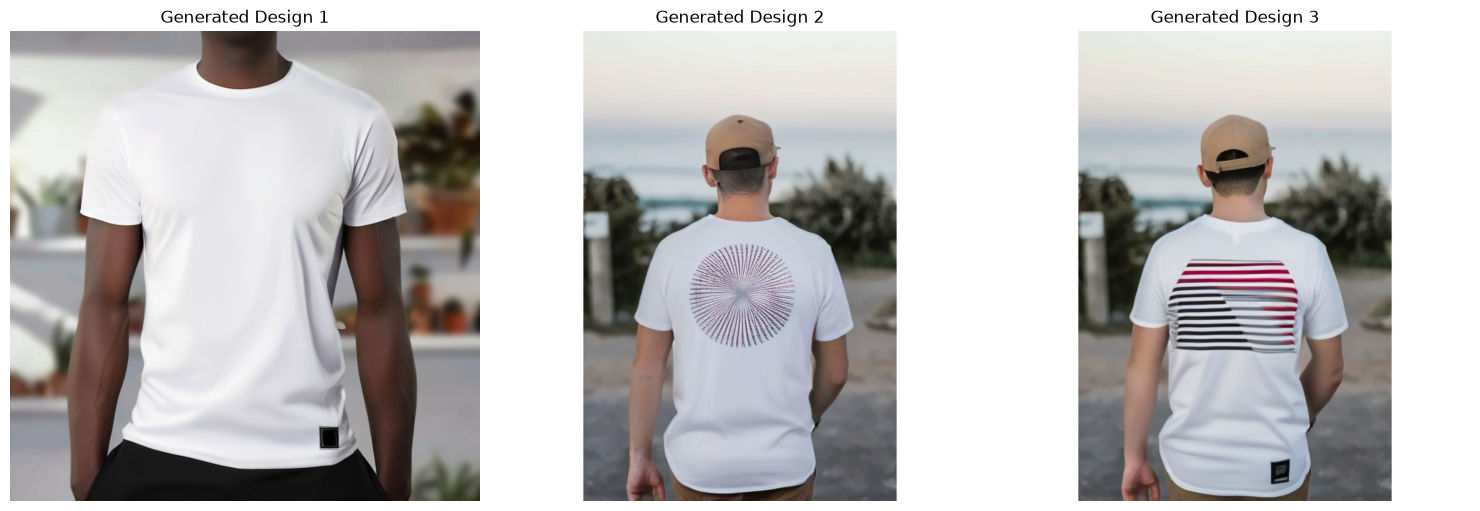

In [17]:
plt.figure(figsize=(15, 5))

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(generated_images[i])
    plt.title("Generated Design " + str(i + 1))
    plt.axis("off")

plt.tight_layout()
plt.show()

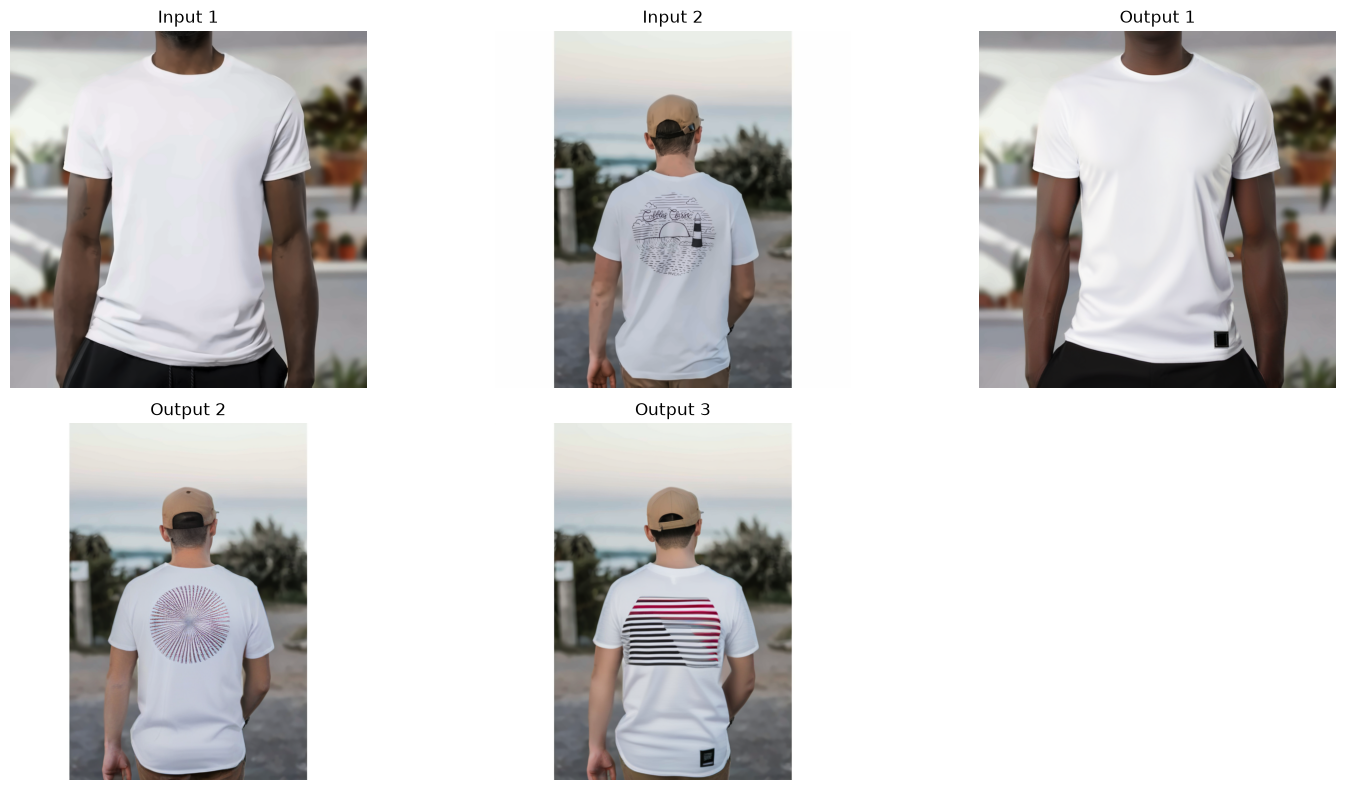

In [18]:
all_images = [
    image_1,
    image_2,
    generated_images[0],
    generated_images[1],
    generated_images[2]
]

titles = [
    "Input 1",
    "Input 2",
    "Output 1",
    "Output 2",
    "Output 3"
]

plt.figure(figsize=(15, 8))

for i in range(5):
    plt.subplot(2, 3, i + 1)
    plt.imshow(all_images[i])
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()